# PS- 5C: Fashion MNIST Transfer Learning Using VGG16

Fashion MNIST is grayscale, so each image is resized and copied into three RGB channels for VGG16.

Fast practical mode: images are 128 x 128, training uses 50 batches for 2 epochs, and fine tuning uses 10 batches for 1 epoch.


In [15]:
# a. Import packages first
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16


In [16]:
# b. Load updated Fashion MNIST class folders and create train/validation datasets.
size = (128, 128)
train_ds = tf.keras.utils.image_dataset_from_directory(
    "fashion mnist", validation_split=0.2, subset="training",
    seed=42, image_size=size, batch_size=16, color_mode="rgb"
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "fashion mnist", validation_split=0.2, subset="validation",
    seed=42, image_size=size, batch_size=16, color_mode="rgb"
)
val_ds = test_ds
class_names = train_ds.class_names


Found 12832 files belonging to 11 classes.
Using 10266 files for training.
Found 12832 files belonging to 11 classes.
Using 2566 files for validation.


In [17]:
# c and d. Load VGG16, freeze it, and add a small classifier.
base = VGG16(weights="vgg16_notop_weights.h5", include_top=False, input_shape=(128, 128, 3))
base.trainable = False
model = models.Sequential([
    layers.Rescaling(1./255),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(11, activation="softmax")
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


In [18]:
# e and f. Train and compute loss.
history = model.fit(train_ds.take(50), validation_data=val_ds.take(10), epochs=2)


Epoch 1/2
50/50 ━━━━━━━━━━━━━━━━━━━━ 68s 1s/step - accuracy: 0.2313 - loss: 2.2177 - val_accuracy: 0.4313 - val_loss: 2.0470
Epoch 2/2
50/50 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.4625 - loss: 1.8419 - val_accuracy: 0.4875 - val_loss: 1.7667


In [19]:
# g. Evaluate loss and accuracy.
loss, accuracy = model.evaluate(test_ds.take(10))
print("Loss:", loss)
print("Accuracy:", accuracy)


10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.5000 - loss: 1.7837  
Loss: 1.7837070226669312
Accuracy: 0.5


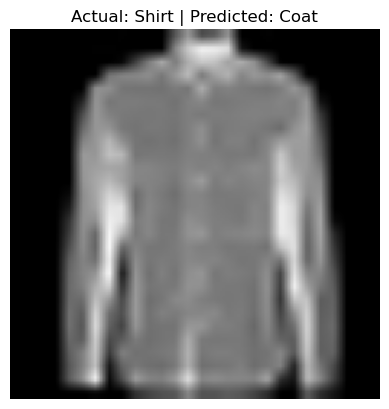

In [20]:
# h. Show one prediction.
for images, labels in test_ds.take(1):
    prediction = tf.argmax(model.predict(images[:1], verbose=0)[0]).numpy()
    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title("Actual: " + class_names[labels[0]] + " | Predicted: " + class_names[prediction])
    plt.axis("off")
    plt.show()


In [21]:
# i. Fine tune the top VGG16 layers.
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds.take(10), validation_data=val_ds.take(10), epochs=1)


10/10 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.5375 - loss: 1.6442 - val_accuracy: 0.5125 - val_loss: 1.5822
